In [1]:
!pip -q install pandas numpy scikit-learn matplotlib joblib openpyxl

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path
project_dir = Path('/content/drive/MyDrive/ECE539_P1')
for folder in ['data', 'splits', 'results', 'models']:
  (project_dir / folder).mkdir(parents=True, exist_ok=True)

In [4]:
import zipfile
from pathlib import Path
data_dir = project_dir / "data"
zip_files = ["features.zip", "DEAM_Annotations.zip"]
for zip_name in zip_files:
  zip_path = data_dir / zip_name
  extract_folder = data_dir / zip_path.stem
  extract_folder.mkdir(parents=True, exist_ok=True)
  with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

In [7]:
import pandas as pd
from pathlib import Path
project_dir = Path("/content/drive/MyDrive/ECE539_P1")
data_dir = project_dir / "data"
annotation_files = sorted((data_dir / "DEAM_Annotations").rglob("static_annotations_averaged_songs_*.csv"))
print("Annotation files found:", len(annotation_files))
annotation_frames = []
for file in annotation_files:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    annotation_frames.append(df)
annotations = pd.concat(annotation_frames, ignore_index=True)
annotations = annotations[["song_id", "valence_mean", "arousal_mean"]].copy()
annotations = annotations.dropna()
annotations = annotations.drop_duplicates(subset="song_id")
feature_files = sorted((data_dir / "features").rglob("*.csv"))


Annotation files found: 2


In [8]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(539)
selected_annotations = annotations.sample(n=500, random_state=539).copy()
feature_lookup = {int(path.stem): path for path in feature_files if path.stem.isdigit()}
combined_rows = []
failed_songs = []
for song in selected_annotations.itertuples(index=False):
    song_id = int(song.song_id)
    if song_id not in feature_lookup:
        failed_songs.append(song_id)
        continue
    try:
        features = pd.read_csv(feature_lookup[song_id], sep=";")
        features = features.drop(columns=["frameTime"], errors="ignore")
        features = features.apply(pd.to_numeric, errors="coerce")
        features = features.replace([np.inf, -np.inf], np.nan)
        mean_features = features.mean(axis=0)
        row = {"song_id": song_id, "valence_mean": song.valence_mean, "arousal_mean": song.arousal_mean}
        row.update(mean_features.to_dict())
        combined_rows.append(row)
    except Exception as error:
        failed_songs.append(song_id)
        print(f"Error with song {song_id}: {error}")
combined_data = pd.DataFrame(combined_rows)
output_path = data_dir / "deam_combined_500.csv"
combined_data.to_csv(output_path, index=False)
print("Songs successfully processed:", len(combined_data))
print("Failed songs:", len(failed_songs))
print("Dataset shape:", combined_data.shape)
print("Saved to:", output_path)
print("\nFIRST 5 ROWS:")
display(combined_data.iloc[:5, :8])

DATASET CREATED!
Songs successfully processed: 500
Failed songs: 0
Dataset shape: (500, 263)
Saved to: /content/drive/MyDrive/ECE539_P1/data/deam_combined_500.csv

FIRST 5 ROWS:


,song_id,valence_mean,arousal_mean,F0final_sma_stddev,F0final_sma_amean,voicingFinalUnclipped_sma_stddev,voicingFinalUnclipped_sma_amean,jitterLocal_sma_stddev
0,813,6.2,6.7,60.481462,165.745243,0.039568,0.769625,0.106483
1,1341,3.5,3.2,22.781002,83.779719,0.072394,0.734145,0.147885
2,1598,4.3,5.5,52.479616,67.652720,0.041646,0.723165,0.100674
3,1644,5.0,5.9,29.713986,74.582132,0.044067,0.736524,0.152377
4,1217,3.9,2.6,44.143755,115.475474,0.025312,0.785425,0.121751


In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd
train_df, temp_df = train_test_split(combined_data, test_size=0.30, random_state=539, shuffle=True)
dev_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=539, shuffle=True)

train_ids = set(train_df["song_id"])
dev_ids = set(dev_df["song_id"])
test_ids = set(test_df["song_id"])
assert train_ids.isdisjoint(dev_ids)
assert train_ids.isdisjoint(test_ids)
assert dev_ids.isdisjoint(test_ids)
split_dir = project_dir / "splits"
split_dir.mkdir(parents=True, exist_ok=True)
train_df.to_csv(split_dir / "train.csv", index=False)
dev_df.to_csv(split_dir / "dev.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)
split_ids = pd.concat([train_df[["song_id"]].assign(split="train"), dev_df[["song_id"]].assign(split="dev"), test_df[["song_id"]].assign(split="test")])
split_ids.to_csv(split_dir / "song_split_ids.csv", index=False)
print("Training songs:", len(train_df))
print("Development songs:", len(dev_df))
print("Testing songs:", len(test_df))
print("Total songs:", len(combined_data))
print("\nNo overlap between splits!")
print("Saved to:", split_dir)


DATASET SPLITS CREATED!
Training songs: 350
Development songs: 75
Testing songs: 75
Total songs: 500

No overlap between splits!
Saved to: /content/drive/MyDrive/ECE539_P1/splits


In [10]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
target_cols = ["valence_mean", "arousal_mean"]
feature_cols = [
    col for col in train_df.columns
    if col not in ["song_id"] + target_cols
]
X_train = train_df[feature_cols]
y_train = train_df[target_cols]
X_dev = dev_df[feature_cols]
y_dev = dev_df[target_cols]
baseline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", LinearRegression())])
baseline.fit(X_train, y_train)
train_pred = baseline.predict(X_train)
dev_pred = baseline.predict(X_dev)
for dataset_name, actual, predicted in [
    ("TRAINING", y_train, train_pred),
    ("DEVELOPMENT", y_dev, dev_pred)
]:
    print(f"\n{dataset_name} RESULTS")

    for i, target in enumerate(target_cols):
        r2 = r2_score(actual.iloc[:, i], predicted[:, i])
        rmse = np.sqrt(
            mean_squared_error(
                actual.iloc[:, i],
                predicted[:, i]
            )
        )

        print(f"{target}:")
        print(f"  R²   = {r2:.4f}")
        print(f"  RMSE = {rmse:.4f}")


TRAINING RESULTS
valence_mean:
  R²   = 0.9055
  RMSE = 0.3516
arousal_mean:
  R²   = 0.9015
  RMSE = 0.3967

DEVELOPMENT RESULTS
valence_mean:
  R²   = -1.6053
  RMSE = 1.7405
arousal_mean:
  R²   = -2.0066
  RMSE = 2.1371


In [11]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
import pandas as pd

alphas = [0.1, 1, 10, 100, 1000]
results = []
for alpha in alphas:
    ridge_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))])
    ridge_model.fit(X_train, y_train)
    predictions = ridge_model.predict(X_dev)
    results.append({
        "alpha": alpha,
        "valence_R2": r2_score(
            y_dev["valence_mean"],
            predictions[:, 0]
        ),
        "valence_RMSE": np.sqrt(
            mean_squared_error(
                y_dev["valence_mean"],
                predictions[:, 0]
            )
        ),
        "arousal_R2": r2_score(
            y_dev["arousal_mean"],
            predictions[:, 1]
        ),
        "arousal_RMSE": np.sqrt(
            mean_squared_error(
                y_dev["arousal_mean"],
                predictions[:, 1]
            )
        )
    })
ridge_results = pd.DataFrame(results)
print("RIDGE REGRESSION RESULTS:")
display(ridge_results.round(4))

RIDGE REGRESSION RESULTS:


,alpha,valence_R2,valence_RMSE,arousal_R2,arousal_RMSE
0,0.1,-0.3356,1.2462,-0.6745,1.5949
1,1.0,-0.0978,1.1298,-0.0940,1.2891
2,10.0,0.1455,0.9968,0.2917,1.0373
3,100.0,0.2128,0.9567,0.3843,0.9671
4,1000.0,0.2324,0.9447,0.3459,0.9968


In [12]:
import joblib
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

model_dir = project_dir / "models"
results_dir = project_dir / "results"
model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(baseline, model_dir / "linear_regression_baseline.joblib")
ridge_final = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", Ridge(alpha=100))])
ridge_final.fit(X_train, y_train)
joblib.dump(ridge_final, model_dir / "ridge_alpha100.joblib")
joblib.dump(feature_cols, model_dir / "feature_columns.joblib")
ridge_results.to_csv(results_dir / "ridge_dev_sweep.csv", index=False)
comparison_rows = []
for name, model in [
    ("Linear Regression", baseline),
    ("Ridge (alpha=100)", ridge_final)
]:
    predictions = model.predict(X_dev)

    for i, target in enumerate(target_cols):
        comparison_rows.append({
            "model": name,
            "target": target,
            "split": "dev",
            "R2": r2_score(
                y_dev.iloc[:, i],
                predictions[:, i]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_dev.iloc[:, i],
                    predictions[:, i]
                )
            )
        })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(results_dir / "baseline_dev_comparison.csv", index=False)
print("MODELS AND RESULTS SAVED!")
print("\nDEVELOPMENT COMPARISON:")
display(comparison.round(4))
print("\nModel directory:", model_dir)
print("Results directory:", results_dir)

MODELS AND RESULTS SAVED!

DEVELOPMENT COMPARISON:


,model,target,split,R2,RMSE
0,Linear Regression,valence_mean,dev,-1.6053,1.7405
1,Linear Regression,arousal_mean,dev,-2.0066,2.1371
2,Ridge (alpha=100),valence_mean,dev,0.2128,0.9567
3,Ridge (alpha=100),arousal_mean,dev,0.3843,0.9671



Model directory: /content/drive/MyDrive/ECE539_P1/models
Results directory: /content/drive/MyDrive/ECE539_P1/results


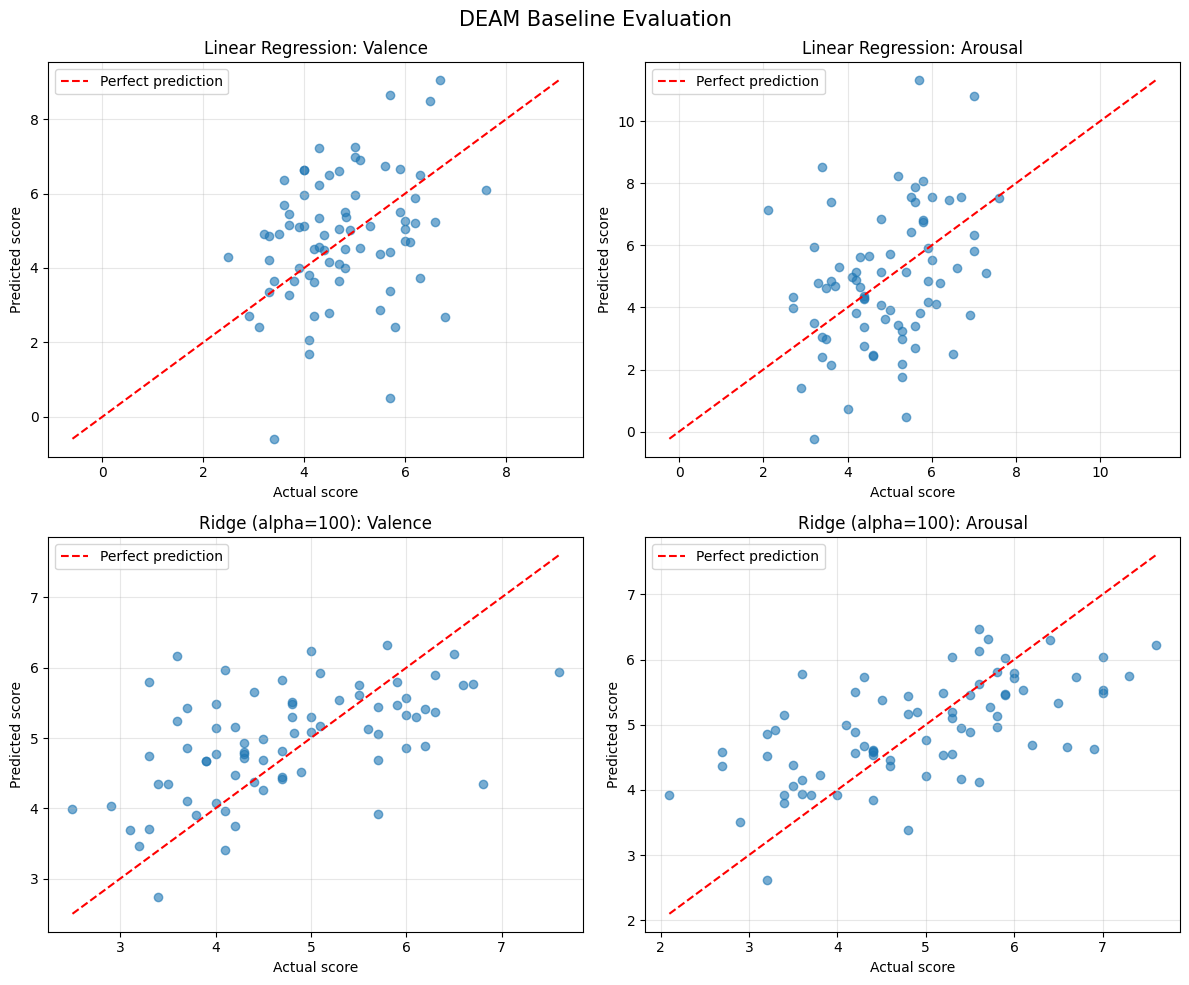

In [13]:
import matplotlib.pyplot as plt
import numpy as np

linear_pred = baseline.predict(X_dev)
ridge_pred = ridge_final.predict(X_dev)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
models = [("Linear Regression", linear_pred), ("Ridge (alpha=100)", ridge_pred)]
targets = ["Valence", "Arousal"]
for row, (model_name, predictions) in enumerate(models):
    for col, target in enumerate(targets):
        ax = axes[row, col]
        actual = y_dev.iloc[:, col].to_numpy()
        predicted = predictions[:, col]
        ax.scatter(actual, predicted, alpha=0.6)
        limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
        ax.plot(limits, limits, linestyle="--", color="red", label="Perfect prediction")
        ax.set_xlabel("Actual score")
        ax.set_ylabel("Predicted score")
        ax.set_title(f"{model_name}: {target}")
        ax.legend()
        ax.grid(alpha=0.3)
plt.suptitle("DEAM Baseline Evaluation", fontsize=15)
plt.tight_layout()
plt.savefig(results_dir / "baseline_prediction_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

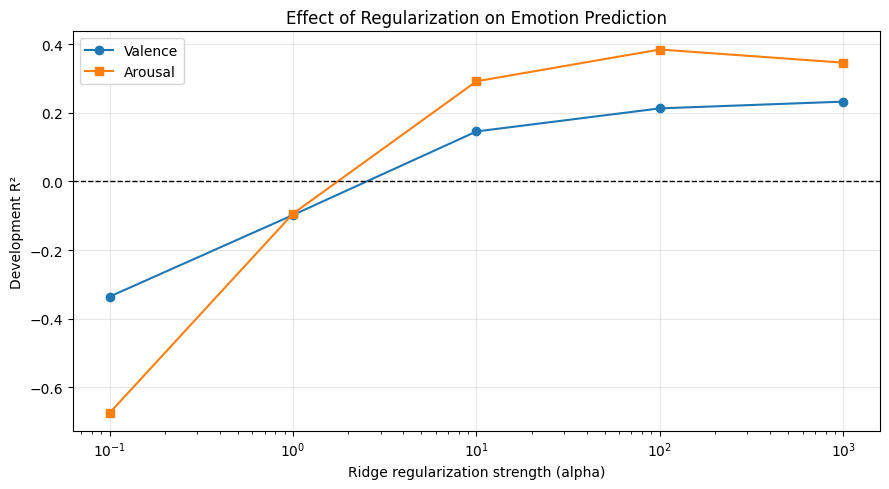

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(ridge_results["alpha"], ridge_results["valence_R2"], marker="o", label="Valence")
ax.semilogx(ridge_results["alpha"], ridge_results["arousal_R2"], marker="s", label="Arousal")
ax.axhline(y=0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Ridge regularization strength (alpha)")
ax.set_ylabel("Development R²")
ax.set_title("Effect of Regularization on Emotion Prediction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / "ridge_regularization_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
import pandas as pd
import numpy as np
ridge_predictions = ridge_final.predict(X_dev)
error_analysis = pd.DataFrame({
    "song_id": dev_df["song_id"].to_numpy(),
    "actual_valence": y_dev["valence_mean"].to_numpy(),
    "predicted_valence": ridge_predictions[:, 0],
    "actual_arousal": y_dev["arousal_mean"].to_numpy(),
    "predicted_arousal": ridge_predictions[:, 1]})
error_analysis["valence_error"] = (error_analysis["predicted_valence"] - error_analysis["actual_valence"])
error_analysis["arousal_error"] = (error_analysis["predicted_arousal"] - error_analysis["actual_arousal"])
error_analysis["combined_absolute_error"] = (error_analysis["valence_error"].abs() + error_analysis["arousal_error"].abs())
error_analysis = error_analysis.sort_values("combined_absolute_error", ascending=False)
error_analysis.to_csv(results_dir / "ridge_dev_error_analysis.csv", index=False)
print("ERROR ANALYSIS SAVED!")
print("\nTOP 10 SONGS WITH THE LARGEST ERRORS:")
display(error_analysis.head(10).round(3))
print("\nAVERAGE ABSOLUTE ERROR:")
print("Valence:", round(error_analysis["valence_error"].abs().mean(), 4))
print("Arousal:", round(error_analysis["arousal_error"].abs().mean(), 4))

ERROR ANALYSIS SAVED!

TOP 10 SONGS WITH THE LARGEST ERRORS:


,song_id,actual_valence,predicted_valence,actual_arousal,predicted_arousal,valence_error,arousal_error,combined_absolute_error
72,286,5.7,3.924,6.9,4.629,-1.776,-2.271,4.047
38,1964,3.6,6.162,6.7,5.727,2.562,-0.973,3.534
73,51,3.6,5.239,3.2,4.861,1.639,1.661,3.300
21,58,3.3,4.746,3.4,5.157,1.446,1.757,3.203
23,1283,3.3,5.791,5.2,4.540,2.491,-0.660,3.151
69,2020,6.8,4.340,5.8,5.130,-2.460,-0.670,3.130
71,1363,5.1,5.931,3.6,5.778,0.831,2.178,3.009
67,1902,4.4,5.659,7.3,5.741,1.259,-1.559,2.818
64,1411,3.9,4.678,2.7,4.576,0.778,1.876,2.655
27,964,7.6,5.937,7.0,6.041,-1.663,-0.959,2.622



AVERAGE ABSOLUTE ERROR:
Valence: 0.757
Arousal: 0.7711
